# 14 · Upgrading the combined detector to the VAR bank

**Why.** The combined detector of notebook 08 (per-KPI CUSUM on all 11 KPIs ∪ coupled latency bank) is the recommended practical detector and the one in the demo. Its coupled part is the bank on the *instantaneous* covariance $\Sigma$ (notebook 07). Notebook 10 found that a bank on jointly **VAR-whitened** latencies is much faster on small slice-local faults: at $s = 0.1$, 18.6–24.2× faster than per-slice CUSUM, against 3.5–19× for the $\Sigma$ bank. It finds barely visible faults ($s = 0.03$) that the $\Sigma$ bank mostly misses. The same notebook also found the VAR bank somewhat worse on a medium capacity drop.

**Question.** Does replacing the $\Sigma$ bank by the VAR bank improve the combined detector on the slice-local faults, without making it worse anywhere? The per-KPI part should cover the shared faults where the VAR bank is weak.

**Set-up.** Everything is as in notebook 08, so the detectors shared with it must reproduce its numbers exactly:
- default scenario, ARL 1000 windows (100 s), all 7 faults at 5 strengths, 32 runs per case, fault at 10 s, 30 s horizon, same seeds;
- the VAR model, VAR(p) with order by BIC, is fitted on the training runs' three raw latency streams;
- its bank uses the same 20 candidate directions, mapped into the innovations by $A(1)$ (notebook 10);
- both combined detectors split the false-alarm budget equally between their two parts and are then jointly calibrated (`calibrate_union`).

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slicead.sim import Fault, load_config, load_fault_scenarios, simulate
from slicead.detectors import CUSUM, CUSUMBank, StreamModel, Union, VARModel, candidate_directions, stream_array
from slicead.eval import calibrate_bank, calibrate_per_stream, calibrate_union, first_alarms, summarize_delays

SEED = 20261022                       # same seeds as notebooks 05-08
OUT = Path("../results/14_combined_var")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"14_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    (REPORT / "tables" / f"14_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"14_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLORS = {"standard (11 KPIs)": "#898781", "Sigma bank": "#eb6834", "VAR bank": "#eda100",
          "combined, Sigma bank": "#2a78d6", "combined, VAR bank": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

cfg = load_config("../configs/sim_default.yaml")
SLICES = ["eMBB", "URLLC", "mMTC"]
KPIS = ["throughput_mbps", "latency_ms", "jitter_ms", "loss_pct"]
STREAMS = [(s, k) for s in SLICES for k in KPIS if not (s == "URLLC" and k == "loss_pct")]
LAT = [STREAMS.index((s, "latency_ms")) for s in SLICES]
TARGET_ARL, CHANGE_S, HORIZON_W = 1000, 10.0, 300
STRENGTHS = [0.03, 0.1, 0.25, 0.5, 1.0]
STD_COLS, LAT_COLS, VAR_COLS, ALL_COLS = list(range(11)), [11, 12, 13], [14, 15, 16], list(range(17))

def detector_input(model, var, X):
    # columns 0-10: raw z-scores of the 11 KPIs; 11-13: AR(1)-whitened latencies; 14-16: VAR innovations
    return np.concatenate([model.standardize(X), model.whiten(X)[:, :, LAT], var.whiten(X[:, :, LAT])], axis=2)

## 1. Models and calibration

In [2]:
t0 = time.time()
train = simulate(cfg, n_windows=3000, n_runs=8, seed=SEED)
calib = simulate(cfg, n_windows=3000, n_runs=32, seed=SEED + 1)
Xtr = stream_array(train, STREAMS)
model = StreamModel().fit(Xtr)
var = VARModel(max_p=30).fit(Xtr[:, :, LAT])
Ztr = detector_input(model, var, Xtr)
Zcal = detector_input(model, var, stream_array(calib, STREAMS))
Sigma = np.corrcoef(Ztr[:, :, LAT_COLS].reshape(-1, 3).T)
C = candidate_directions(3)
print(f"VAR order (BIC): {var.p}")

standard = CUSUM(0.5)
c_std, _ = calibrate_per_stream(standard, Zcal[:, :, STD_COLS], TARGET_ARL)
sbank = CUSUMBank(C, Sigma)
c_sbank, _ = calibrate_bank(sbank, Zcal[:, :, LAT_COLS], TARGET_ARL)
vbank = CUSUMBank(var.residual_directions(C), var.Sigma_e)
c_vbank, _ = calibrate_bank(vbank, Zcal[:, :, VAR_COLS], TARGET_ARL)

def make_union(bank, cols, c_bank):
    std_part, bank_part = CUSUM(0.5), CUSUMBank(bank.directions, bank.Sigma)
    std_part.scale, bank_part.scale = standard.scale.copy(), bank.scale.copy()
    u = Union([(std_part, STD_COLS, c_std), (bank_part, cols, c_bank)], sizes=[11, 20])
    c, arl = calibrate_union(u, Zcal, TARGET_ARL)
    return u, c, arl

comb_s, c_comb_s, arl_s = make_union(sbank, LAT_COLS, c_sbank)
comb_v, c_comb_v, arl_v = make_union(vbank, VAR_COLS, c_vbank)
print(f"calibrated in {time.time() - t0:.0f} s")
print(f"stand-alone thresholds: standard {c_std:.3f}, Sigma bank {c_sbank:.3f}, VAR bank {c_vbank:.3f}")
for name, u, c, arl in [("Sigma bank", comb_s, c_comb_s, arl_s), ("VAR bank", comb_v, c_comb_v, arl_v)]:
    print(f"combined with {name}: parts {u.parts[0][2]:.3f} / {u.parts[1][2]:.3f}, factor {c:.3f}, ARL {arl:.0f}")

VAR order (BIC): 3


calibrated in 276 s
stand-alone thresholds: standard 0.945, Sigma bank 0.978, VAR bank 0.894
combined with Sigma bank: parts 1.039 / 1.023, factor 0.991, ARL 1000
combined with VAR bank: parts 1.039 / 0.993, factor 0.982, ARL 1000


## 2. The sweep

All 7 faults at 5 strengths, with the same seeds as notebook 08. The standard detector, the $\Sigma$ bank and the combined detector with the $\Sigma$ bank are notebook 08's detectors, so their delays must match notebook 08 exactly.

In [3]:
SCENARIOS = load_fault_scenarios("../configs/faults.yaml", start_s=CHANGE_S)
NICE = {"capacity_drop": "capacity drop", "capacity_degradation": "capacity degradation",
        "embb_surge": "eMBB surge", "urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm",
        "urllc_loss_burst": "URLLC loss burst", "urllc_weight_misconfig": "URLLC weight misconfig."}
DETS = {"standard (11 KPIs)": (standard, STD_COLS, c_std), "Sigma bank": (sbank, LAT_COLS, c_sbank),
        "VAR bank": (vbank, VAR_COLS, c_vbank),
        "combined, Sigma bank": (comb_s, ALL_COLS, c_comb_s),     # a Union indexes the full input itself
        "combined, VAR bank": (comb_v, ALL_COLS, c_comb_v)}

def scaled(faults, s):
    return [Fault(f.kind, f.start_s, f.factor ** s, f.slice, f.ramp_s) for f in faults]

rows, part_hits = [], []
t0 = time.time()
for i, (scen, faults) in enumerate(SCENARIOS.items()):
    for j, s in enumerate(STRENGTHS):
        res = simulate(cfg, n_windows=400, n_runs=32, seed=SEED + 100 + 10 * i + j, faults=scaled(faults, s))
        Z = detector_input(model, var, stream_array(res, STREAMS))
        for name, (det, cols, c) in DETS.items():
            t_alarm, which = first_alarms(det, Z[:, :, cols], c)
            rows.append(dict(scenario=NICE[scen], strength=s, detector=name,
                             **summarize_delays(t_alarm, res.fault_window, HORIZON_W, res.window_s)))
            if name == "combined, VAR bank":
                hit = t_alarm >= res.fault_window
                parts = [det.decode(int(w))[0] for w in which[hit]]
                part_hits.append(dict(scenario=NICE[scen], strength=s,
                                      share_bank=np.mean(parts) if parts else np.nan))
sweep = pd.DataFrame(rows)
sweep.to_csv(OUT / "sweep.csv", index=False)
part_hits = pd.DataFrame(part_hits)
print(f"sweep simulated and scored in {time.time() - t0:.0f} s")

# notebook 08 used the same seeds and detectors: its numbers must be reproduced exactly
nb08 = pd.read_csv("../results/08_combined_detector/sweep.csv").set_index(["scenario", "strength", "detector"]).delay_mean_s
same = {"standard (11 KPIs)": "standard (11 KPIs)", "Sigma bank": "coupled bank (latency)",
        "combined, Sigma bank": "combined"}
for mine, theirs in same.items():
    a = sweep[sweep.detector == mine].set_index(["scenario", "strength"]).delay_mean_s
    b = nb08.xs(theirs, level="detector").reindex(a.index)
    print(f"{mine:22s} vs notebook 08, max |difference|: {float((a - b).abs().max()):.2e}")
P = sweep.pivot_table(index=["scenario", "strength"], columns="detector", values="delay_mean_s")[list(DETS)]
P.round(2)

sweep simulated and scored in 271 s


standard (11 KPIs)     vs notebook 08, max |difference|: 3.55e-15
Sigma bank             vs notebook 08, max |difference|: 3.55e-15
combined, Sigma bank   vs notebook 08, max |difference|: 3.55e-15


detector                          standard (11 KPIs)  Sigma bank  VAR bank  \
scenario                strength                                             
URLLC loss burst        0.03                   25.19       26.50     26.68   
                        0.10                   24.71       24.28     24.09   
                        0.25                   26.76       25.54     25.97   
                        0.50                   27.41       26.83     26.45   
                        1.00                   26.62       27.47     27.03   
URLLC surge             0.03                    2.70       23.32      7.70   
                        0.10                    0.40        3.33      0.62   
                        0.25                    0.19        0.23      0.24   
                        0.50                    0.10        0.10      0.10   
                        1.00                    0.10        0.10      0.10   
URLLC weight misconfig. 0.03                   21.55       16.92      1.63   
                        0.10                    4.11        0.40      0.31   
                        0.25                    0.93        0.10      0.12   
                        0.50                    0.31        0.10      0.10   
                        1.00                    0.10        0.10      0.10   
capacity degradation    0.03                   27.50       28.07     27.55   
                        0.10                   26.29       28.29     26.69   
                        0.25                   27.37       25.39     26.13   
                        0.50                   23.34       22.60     23.37   
                        1.00                   16.98       19.30     21.46   
capacity drop           0.03                   27.87       26.89     25.97   
                        0.10                   22.64       21.95     24.08   
                        0.25                   11.44       15.58     19.55   
                        0.50                    3.51        5.61      4.87   
                        1.00                    1.14        0.64      0.78   
eMBB surge              0.03                   26.19       25.86     25.84   
                        0.10                   25.22       24.94     22.10   
                        0.25                   19.77       25.36     23.57   
                        0.50                   13.80       26.25     18.72   
                        1.00                    4.48       18.10      9.57   
mMTC storm              0.03                    0.80       23.68      5.83   
                        0.10                    0.22        2.91      0.69   
                        0.25                    0.10        0.14      0.23   
                        0.50                    0.10        0.10      0.10   
                        1.00                    0.10        0.10      0.10   

detector                          combined, Sigma bank  combined, VAR bank  
scenario                strength                                            
URLLC loss burst        0.03                     27.65               26.34  
                        0.10                     21.92               23.76  
                        0.25                     25.35               27.95  
                        0.50                     27.89               25.80  
                        1.00                     28.58               26.87  
URLLC surge             0.03                      2.98                2.64  
                        0.10                      0.42                0.45  
                        0.25                      0.18                0.19  
                        0.50                      0.10                0.10  
                        1.00                      0.10                0.10  
URLLC weight misconfig. 0.03                     17.44                1.73  
                        0.10                      0.43                0.33  
                        0.25       

In [4]:
sweep.pivot_table(index=["scenario", "strength"], columns="detector", values="detected")[list(DETS)].round(2)

detector                          standard (11 KPIs)  Sigma bank  VAR bank  \
scenario                strength                                             
URLLC loss burst        0.03                    0.25        0.22      0.21   
                        0.10                    0.34        0.31      0.36   
                        0.25                    0.27        0.26      0.25   
                        0.50                    0.26        0.19      0.25   
                        1.00                    0.22        0.20      0.24   
URLLC surge             0.03                    1.00        0.44      0.93   
                        0.10                    1.00        1.00      1.00   
                        0.25                    1.00        1.00      1.00   
                        0.50                    1.00        1.00      1.00   
                        1.00                    1.00        1.00      1.00   
URLLC weight misconfig. 0.03                    0.44        0.75      1.00   
                        0.10                    1.00        1.00      1.00   
                        0.25                    1.00        1.00      1.00   
                        0.50                    1.00        1.00      1.00   
                        1.00                    1.00        1.00      1.00   
capacity degradation    0.03                    0.21        0.17      0.21   
                        0.10                    0.25        0.14      0.20   
                        0.25                    0.24        0.28      0.33   
                        0.50                    0.62        0.50      0.54   
                        1.00                    1.00        0.87      0.80   
capacity drop           0.03                    0.12        0.20      0.23   
                        0.10                    0.45        0.45      0.38   
                        0.25                    1.00        0.86      0.65   
                        0.50                    1.00        1.00      1.00   
                        1.00                    1.00        1.00      1.00   
eMBB surge              0.03                    0.16        0.19      0.23   
                        0.10                    0.25        0.29      0.42   
                        0.25                    0.63        0.25      0.42   
                        0.50                    0.81        0.40      0.77   
                        1.00                    1.00        0.67      0.93   
mMTC storm              0.03                    1.00        0.41      1.00   
                        0.10                    1.00        1.00      1.00   
                        0.25                    1.00        1.00      1.00   
                        0.50                    1.00        1.00      1.00   
                        1.00                    1.00        1.00      1.00   

detector                          combined, Sigma bank  combined, VAR bank  
scenario                strength                                            
URLLC loss burst        0.03                      0.16                0.17  
                        0.10                      0.39                0.37  
                        0.25                      0.30                0.19  
                        0.50                      0.21                0.33  
                        1.00                      0.10                0.16  
URLLC surge             0.03                      1.00                1.00  
                        0.10                      1.00                1.00  
                        0.25                      1.00                1.00  
                        0.50                      1.00                1.00  
                        1.00                      1.00                1.00  
URLLC weight misconfig. 0.03                      0.72                1.00  
                        0.10                      1.00                1.00  
                        0.25       

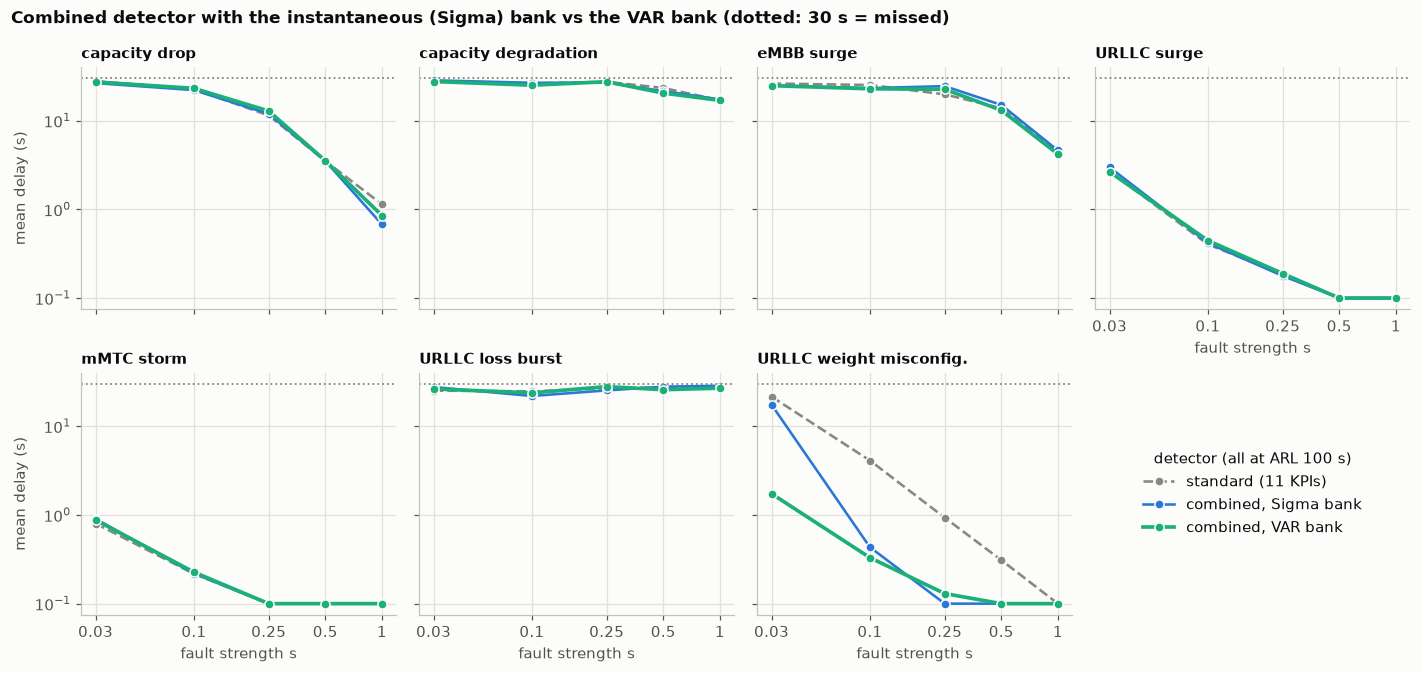

In [5]:
order = list(NICE.values())
fig, axes = plt.subplots(2, 4, figsize=(13, 6.2), sharex=True, sharey=True)
for ax, scen in zip(axes.ravel(), order):
    g = sweep[sweep.scenario == scen]
    for det, col in COLORS.items():
        if det in ("Sigma bank", "VAR bank"):
            continue
        d = g[g.detector == det].sort_values("strength")
        ax.plot(d.strength, d.delay_mean_s, marker="o", color=col, label=det, mec=SURFACE, mew=1,
                ls="--" if det == "standard (11 KPIs)" else "-", lw=2.4 if det == "combined, VAR bank" else 1.7)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axhline(30, color=MUTED, ls=":", lw=1.2)
    ax.set_title(scen, fontsize=10)
    ax.set_xticks(STRENGTHS, [f"{s:g}" for s in STRENGTHS]); ax.minorticks_off()
axes.ravel()[-1].axis("off")
h, l = axes[0, 0].get_legend_handles_labels()
axes.ravel()[-1].legend(h, l, loc="center", title="detector (all at ARL 100 s)")
for ax in axes[1]:
    ax.set_xlabel("fault strength s")
axes[0, 3].set_xlabel("fault strength s"); axes[0, 3].xaxis.set_tick_params(labelbottom=True)
for ax in axes[:, 0]:
    ax.set_ylabel("mean delay (s)")
fig.suptitle("Combined detector with the instantaneous (Sigma) bank vs the VAR bank (dotted: 30 s = missed)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig1_combined_var_sweep")
plt.show()

## 3. Is the new combined detector better, and is it worse anywhere?

For each fault and strength we compare:
- the new combined detector against the old one;
- the new combined detector against the better of its two parts on their own, as in notebook 08.

Cells where no detector does better than chance (best mean delay above 25 s) are flagged, because ratios there are noise.

In [6]:
cmp = pd.DataFrame({
    "old combined": P["combined, Sigma bank"], "new combined": P["combined, VAR bank"],
    "new / old": P["combined, VAR bank"] / P["combined, Sigma bank"],
    "new / best part": P["combined, VAR bank"] / P[["standard (11 KPIs)", "VAR bank"]].min(axis=1),
})
cmp["informative"] = P[list(DETS)].min(axis=1) < 25
cmp = cmp.join(part_hits.set_index(["scenario", "strength"]))
cmp.to_csv(OUT / "comparison.csv")
inf = cmp[cmp.informative]
overall = sweep.groupby("detector").agg(mean_delay=("delay_mean_s", "mean"), detected=("detected", "mean")).loc[list(DETS)]
print(f"informative cells: {len(inf)} of {len(cmp)}")
print(f"new / old combined: median {inf['new / old'].median():.2f}, range {inf['new / old'].min():.2f}-{inf['new / old'].max():.2f}; "
      f"faster (<0.9) in {(inf['new / old'] < 0.9).sum()}, slower (>1.1) in {(inf['new / old'] > 1.1).sum()}")
print(f"new combined / best part: median {inf['new / best part'].median():.2f}, max {inf['new / best part'].max():.2f}")
display(overall.round(2))
cmp.round(2)

informative cells: 27 of 35
new / old combined: median 1.00, range 0.10-1.30; faster (<0.9) in 4, slower (>1.1) in 2
new combined / best part: median 1.00, max 1.14


,mean_delay,detected
detector,,
standard (11 KPIs),12.57,0.70
Sigma bank,14.77,0.63
VAR bank,12.81,0.70
"combined, Sigma bank",12.36,0.71
"combined, VAR bank",11.73,0.73


old combined  new combined  new / old  \
scenario                strength                                          
URLLC loss burst        0.03             27.65         26.34       0.95   
                        0.10             21.92         23.76       1.08   
                        0.25             25.35         27.95       1.10   
                        0.50             27.89         25.80       0.92   
                        1.00             28.58         26.87       0.94   
URLLC surge             0.03              2.98          2.64       0.89   
                        0.10              0.42          0.45       1.07   
                        0.25              0.18          0.19       1.06   
                        0.50              0.10          0.10       1.00   
                        1.00              0.10          0.10       1.00   
URLLC weight misconfig. 0.03             17.44          1.73       0.10   
                        0.10              0.43          0.33       0.76   
                        0.25              0.10          0.13       1.30   
                        0.50              0.10          0.10       1.00   
                        1.00              0.10          0.10       1.00   
capacity degradation    0.03             28.47         27.59       0.97   
                        0.10             26.68         25.07       0.94   
                        0.25             26.81         27.46       1.02   
                        0.50             21.51         20.43       0.95   
                        1.00             17.34         16.91       0.97   
capacity drop           0.03             26.48         27.25       1.03   
                        0.10             22.08         23.12       1.05   
                        0.25             11.93         12.84       1.08   
                        0.50              3.51          3.53       1.01   
                        1.00              0.68          0.85       1.26   
eMBB surge              0.03             24.94         24.77       0.99   
                        0.10             23.24         22.86       0.98   
                        0.25             24.48         22.56       0.92   
                        0.50             15.03         13.08       0.87   
                        1.00              4.61          4.20       0.91   
mMTC storm              0.03              0.90          0.88       0.97   
                        0.10              0.22          0.23       1.04   
                        0.25              0.10          0.10       1.00   
                        0.50              0.10          0.10       1.00   
                        1.00              0.10          0.10       1.00   

                                  new / best part  informative  share_bank  
scenario                strength                                            
URLLC loss burst        0.03                 1.05        False        0.80  
                        0.10                 0.99         True        0.36  
                        0.25                 1.08        False        0.33  
                        0.50                 0.98        False        0.50  
                        1.00                 1.01        False        0.40  
URLLC surge             0.03                 0.98         True        0.03  
                        0.10                 1.10         True        0.06  
                        0.25                 1.02         True        0.04  
                        0.50                 1.00         True        0.00  
                        1.00                 1.00         True        0.00  
URLLC weight misconfig. 0.03                 1.06         True        0.97  
                        0.10                 1.07         True        1.00  
                        0.25                 1.08         True        1.00  
                        0.50                 1.00         True        1.00  
                        1.

**What it shows: the VAR bank improves the combined detector where it matters, and costs nothing visible elsewhere**

- **Reproduction.** The standard detector, the $\Sigma$ bank and the old combined detector reproduce notebook 08 exactly (largest difference $4\times10^{-15}$ s), so the comparison is like for like.
- **The delay-only fault gains a lot.** For the URLLC weight misconfiguration at $s = 0.03$, the combined detector's mean delay drops from 17.4 s to **1.7 s**, and it now finds 100% of faults instead of 72%. At $s = 0.1$ it drops from 0.43 s to 0.33 s.
- **Overall it is better.** The mean delay over all 35 cells is 11.7 s against 12.4 s, and 73% of faults are found within 30 s against 71%.
- **Nothing gets meaningfully worse.**
  - Over the 27 informative cells, new/old has median 1.00.
  - It is faster by more than 10% in 4 cells and slower by more than 10% in 2: the weight misconfiguration at $s = 0.25$ (0.10 → 0.13 s) and the full capacity drop (0.68 → 0.85 s). Both are well under a second.
  - Against the better of its two parts it has median 1.00 and worst case 1.14, as in notebook 08.
- **Inside the combined detector, the VAR bank's other gains are hidden.** On its own, the VAR bank finds small URLLC surges and mMTC storms much faster than the $\Sigma$ bank: at $s = 0.03$, 7.7 s against 23.3 s, and 5.8 s against 23.7 s. But the per-KPI part already catches those faults through throughput (2.7 s and 0.8 s), so the combined detector barely changes there. Its gain is concentrated on faults visible only in delay.

In [7]:
# Export tables and key numbers for report/main.tex
rows = []
for scen in order:
    for s in STRENGTHS:
        r = {"fault": scen, "$s$": f"{s:g}"}
        for d in ["standard (11 KPIs)", "combined, Sigma bank", "combined, VAR bank"]:
            g = sweep[(sweep.scenario == scen) & (sweep.strength == s) & (sweep.detector == d)].iloc[0]
            r[d] = f"{g.delay_mean_s:.1f}" if g.detected >= 0.995 else f"{g.delay_mean_s:.1f} ({100 * g.detected:.0f}\\%)"
        rows.append(r)
tab = pd.DataFrame(rows)
tab["fault"] = [f if i == 0 or f != tab.fault[i - 1] else "" for i, f in enumerate(tab.fault)]
tab.columns = ["fault", "$s$", "standard", "combined, $\\Sigma$ bank", "combined, VAR bank"]
save_tex_table(tab, "sweep", "llrrr")

def d(scen, s, det):
    return P.loc[(scen, s), det]
save_tex_numbers({
    "CvMeanStd": f"{overall.loc['standard (11 KPIs)', 'mean_delay']:.1f}",
    "CvMeanOld": f"{overall.loc['combined, Sigma bank', 'mean_delay']:.1f}",
    "CvMeanNew": f"{overall.loc['combined, VAR bank', 'mean_delay']:.1f}",
    "CvDetOld": f"{100 * overall.loc['combined, Sigma bank', 'detected']:.0f}",
    "CvDetNew": f"{100 * overall.loc['combined, VAR bank', 'detected']:.0f}",
    "CvInformative": f"{len(inf)}",
    "CvRatioMedian": f"{inf['new / old'].median():.2f}",
    "CvRatioMin": f"{inf['new / old'].min():.2f}", "CvRatioMax": f"{inf['new / old'].max():.2f}",
    "CvFaster": f"{(inf['new / old'] < 0.9).sum()}", "CvSlower": f"{(inf['new / old'] > 1.1).sum()}",
    "CvBestMedian": f"{inf['new / best part'].median():.2f}", "CvBestMax": f"{inf['new / best part'].max():.2f}",
    "CvMisOld": f"{d('URLLC weight misconfig.', 0.03, 'combined, Sigma bank'):.1f}",
    "CvMisNew": f"{d('URLLC weight misconfig.', 0.03, 'combined, VAR bank'):.1f}",
    "CvSurgeOld": f"{d('URLLC surge', 0.03, 'combined, Sigma bank'):.1f}",
    "CvSurgeNew": f"{d('URLLC surge', 0.03, 'combined, VAR bank'):.1f}",
    "CvStormOld": f"{d('mMTC storm', 0.03, 'combined, Sigma bank'):.1f}",
    "CvStormNew": f"{d('mMTC storm', 0.03, 'combined, VAR bank'):.1f}",
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("14_*")))

exported: ['14_numbers.tex', '14_sweep.tex']


## Summary

- **The combined detector now uses the VAR bank as its coupled part.** It is the project's recommended detector, and the demo (`demo/prepare.py`, `demo/app.py`) has been switched to it.
- **What improved:** small scheduling-weight misconfigurations, a fault that changes no traffic, are now found in about 1.7 s instead of 17 s at $s = 0.03$, and every time. The overall mean delay improves from 12.4 s to 11.7 s.
- **What did not change:** shared capacity faults below about 8% and the URLLC loss burst remain undetected. These need more information (capacity separated from load) and a count model.